In [ ]:
from pathlib import Path
from urllib.parse import urljoin
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup

# Project folders
PROJECT_DIR = Path("/content/web-scraping-book-analysis")
DATA_DIR = PROJECT_DIR / "data"
CHART_DIR = PROJECT_DIR / "charts"

DATA_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

START_URL = "https://books.toscrape.com/"
OUTPUT_FILE = DATA_DIR / "books_dataset.csv"

HEADERS = {
    "User-Agent": "StudentWebScrapingProject/1.0"
}

RATINGS = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

def download_page(url):
    response = requests.get(
        url,
        headers=HEADERS,
        timeout=20
    )
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")

def extract_book(book, page_url):
    title_tag = book.select_one("h3 a")
    price_tag = book.select_one(".price_color")
    availability_tag = book.select_one(".availability")
    rating_tag = book.select_one(".star-rating")

    if not all([
        title_tag,
        price_tag,
        availability_tag,
        rating_tag
    ]):
        return None

    price_text = (
        price_tag.get_text(strip=True)
        .replace("£", "")
        .replace("Â", "")
    )

    try:
        price = float(price_text)
    except ValueError:
        return None

    rating = None
    for css_class in rating_tag.get("class", []):
        if css_class in RATINGS:
            rating = RATINGS[css_class]
            break

    return {
        "title": title_tag.get("title", "").strip(),
        "price_gbp": price,
        "rating": rating,
        "availability": " ".join(
            availability_tag.get_text(" ", strip=True).split()
        ),
        "product_url": urljoin(
            page_url, title_tag.get("href", "")
        )
    }

# Scrape the website page by page
current_url = START_URL
visited_urls = set()
records = []
MAX_PAGES = 50

for page_number in range(1, MAX_PAGES + 1):
    if not current_url or current_url in visited_urls:
        break

    print(f"Scraping page {page_number}...")
    visited_urls.add(current_url)

    try:
        soup = download_page(current_url)
    except requests.RequestException as error:
        print("Page download failed:", error)
        break

    books = soup.select("article.product_pod")

    if not books:
        print("No book listings found. Stopping.")
        break

    for book in books:
        record = extract_book(book, current_url)
        if record:
            records.append(record)

    next_button = soup.select_one("li.next a")

    if next_button:
        current_url = urljoin(
            current_url, next_button.get("href", "")
        )
    else:
        current_url = None

    time.sleep(1)  # polite delay between requests

# Save scraped data
columns = [
    "title",
    "price_gbp",
    "rating",
    "availability",
    "product_url"
]

df = pd.DataFrame(records, columns=columns)
df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

print("\nSCRAPING COMPLETED")
print("Books collected:", len(df))
print("CSV saved to:", OUTPUT_FILE)
display(df.head())

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...

SCRAPING

,title,price_gbp,rating,availability,product_url
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [ ]:
!pip -q install requests beautifulsoup4 pandas matplotlib

In [ ]:
import pandas as pd

INPUT_FILE = DATA_DIR / "books_dataset.csv"
CLEAN_FILE = DATA_DIR / "books_cleaned.csv"

df = pd.read_csv(INPUT_FILE)

print("Rows before cleaning:", len(df))


df["title"] = df["title"].astype("string").str.strip()
df["price_gbp"] = pd.to_numeric(
    df["price_gbp"], errors="coerce"
)
df["rating"] = pd.to_numeric(
    df["rating"], errors="coerce"
)


df = df.dropna(subset=["title", "price_gbp"])
df = df[df["title"] != ""]
df = df[df["price_gbp"] >= 0]
df = df[
    df["rating"].isna()
    | df["rating"].between(1, 5)
]
df = df.drop_duplicates(subset=["product_url"])

df.to_csv(CLEAN_FILE, index=False, encoding="utf-8-sig")

print("Rows after cleaning:", len(df))
print(f"Average price: £{df['price_gbp'].mean():.2f}")
print(f"Minimum price: £{df['price_gbp'].min():.2f}")
print(f"Maximum price: £{df['price_gbp'].max():.2f}")
print(f"Average rating: {df['rating'].mean():.2f}")

print("\nNumber of books by rating:")
print(df["rating"].value_counts().sort_index())

display(df.head(10))

Rows before cleaning: 1000
Rows after cleaning: 1000
Average price: £35.07
Minimum price: £10.00
Maximum price: £59.99
Average rating: 2.92

Number of books by rating:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


,title,price_gbp,rating,availability,product_url
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


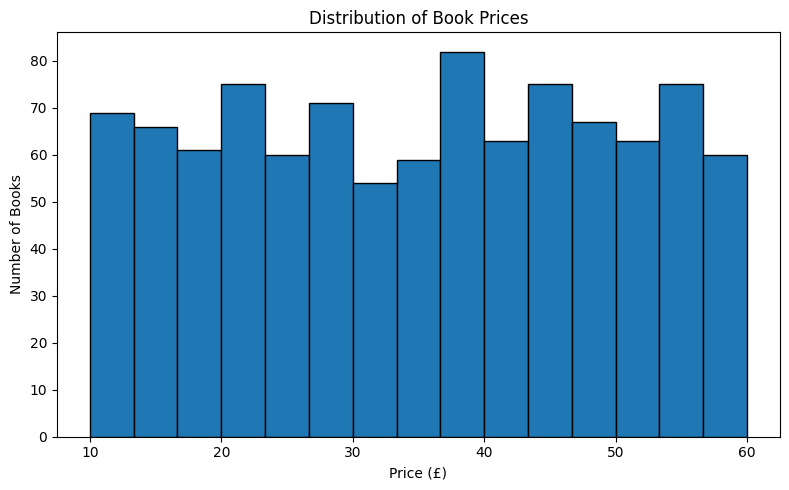

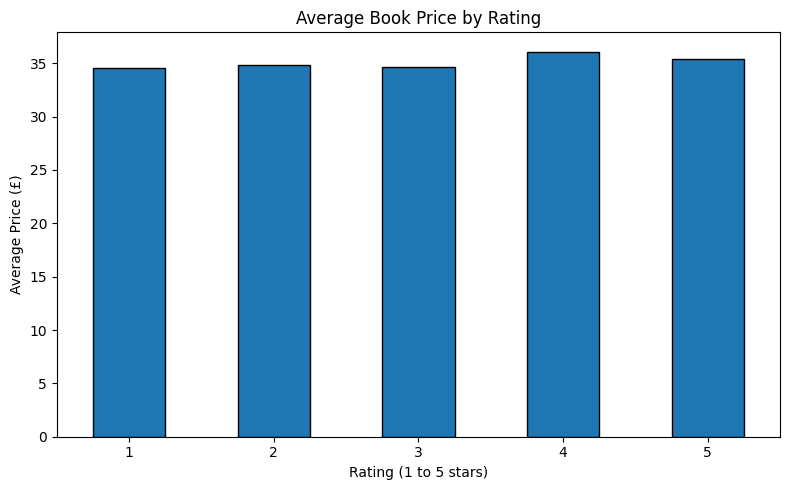

Charts saved in: /content/web-scraping-book-analysis/charts


In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(df["price_gbp"], bins=15, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()

plt.savefig(CHART_DIR / "price_distribution.png", dpi=150)
plt.show()
plt.close()
rating_prices = (
    df.dropna(subset=["rating"])
      .groupby("rating")["price_gbp"]
      .mean()
)

if not rating_prices.empty:
    plt.figure(figsize=(8, 5))
    rating_prices.plot(kind="bar", edgecolor="black")
    plt.title("Average Book Price by Rating")
    plt.xlabel("Rating (1 to 5 stars)")
    plt.ylabel("Average Price (£)")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(CHART_DIR / "price_by_rating.png", dpi=150)
    plt.show()
    plt.close()

print("Charts saved in:", CHART_DIR)

In [5]:
import pandas as pd

INPUT_FILE = DATA_DIR / "books_dataset.csv"
CLEAN_FILE = DATA_DIR / "books_cleaned.csv"

df = pd.read_csv(INPUT_FILE)

print("Rows before cleaning:", len(df))

df["title"] = df["title"].astype("string").str.strip()
df["price_gbp"] = pd.to_numeric(
    df["price_gbp"], errors="coerce"
)
df["rating"] = pd.to_numeric(
    df["rating"], errors="coerce"
)

df = df.dropna(subset=["title", "price_gbp"])
df = df[df["title"] != ""]
df = df[df["price_gbp"] >= 0]
df = df[
    df["rating"].isna()
    | df["rating"].between(1, 5)
]
df = df.drop_duplicates(subset=["product_url"])

df.to_csv(CLEAN_FILE, index=False, encoding="utf-8-sig")

print("Rows after cleaning:", len(df))
print(f"Average price: £{df['price_gbp'].mean():.2f}")
print(f"Minimum price: £{df['price_gbp'].min():.2f}")
print(f"Maximum price: £{df['price_gbp'].max():.2f}")
print(f"Average rating: {df['rating'].mean():.2f}")

print("\nNumber of books by rating:")
print(df["rating"].value_counts().sort_index())

display(df.head(10))

Rows before cleaning: 1000
Rows after cleaning: 1000
Average price: £35.07
Minimum price: £10.00
Maximum price: £59.99
Average rating: 2.92

Number of books by rating:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


,title,price_gbp,rating,availability,product_url
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


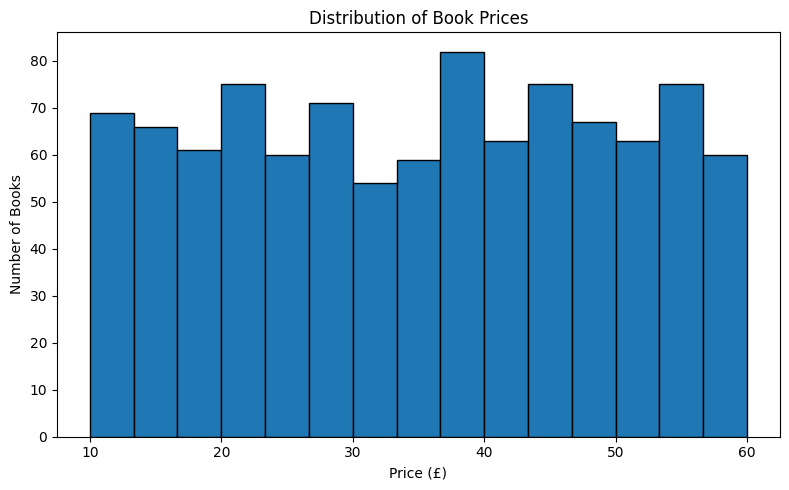

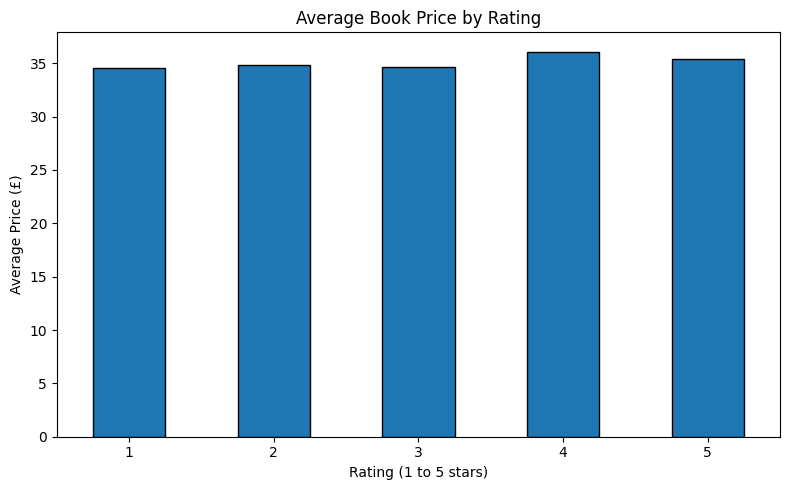

Charts saved in: /content/web-scraping-book-analysis/charts


In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["price_gbp"], bins=15, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()

plt.savefig(CHART_DIR / "price_distribution.png", dpi=150)
plt.show()
plt.close()

rating_prices = (
    df.dropna(subset=["rating"])
      .groupby("rating")["price_gbp"]
      .mean()
)

if not rating_prices.empty:
    plt.figure(figsize=(8, 5))
    rating_prices.plot(kind="bar", edgecolor="black")
    plt.title("Average Book Price by Rating")
    plt.xlabel("Rating (1 to 5 stars)")
    plt.ylabel("Average Price (£)")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(CHART_DIR / "price_by_rating.png", dpi=150)
    plt.show()
    plt.close()

print("Charts saved in:", CHART_DIR)

In [9]:

from pathlib import Path

# Project folders
PROJECT_DIR = Path("/content/web-scraping-book-analysis")
DATA_DIR = PROJECT_DIR / "data"
CHART_DIR = PROJECT_DIR / "charts"

DATA_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

# Create README.md
readme_text = """# Web Scraping and Book Price Analysis

## Project Overview
This project scrapes book information from Books to Scrape,
cleans the dataset, analyzes book prices and ratings,
and creates visualizations.

## Objectives
- Collect book titles, prices, ratings and availability.
- Store scraped data in CSV format.
- Clean and validate the dataset.
- Analyze prices and ratings.
- Generate charts.

## Technologies Used
- Python
- Requests
- Beautiful Soup
- Pandas
- Matplotlib
- Google Colab

## Dataset Columns
- title
- price_gbp
- rating
- availability
- product_url

## Project Structure
- web_scraping_book_analysis.ipynb
- data/books_dataset.csv
- data/books_cleaned.csv
- charts/price_distribution.png
- charts/price_by_rating.png
- requirements.txt

## Data Source
https://books.toscrape.com/

Books to Scrape is a practice website for web scraping.

## How to Run
1. Open the notebook in Google Colab.
2. Install the required libraries.
3. Run each code cell from top to bottom.
4. Review the generated CSV files and charts.

## Results
The notebook generates a book dataset, cleaned data,
summary statistics, and price analysis charts.

## Limitations
Results depend on the website content at the time of scraping.

## License
For educational purposes.
"""

(PROJECT_DIR / "README.md").write_text(
    readme_text, encoding="utf-8"
)

# Create requirements.txt
requirements_text = """requests
beautifulsoup4
pandas
matplotlib
"""

(PROJECT_DIR / "requirements.txt").write_text(
    requirements_text, encoding="utf-8"
)

print("README.md created")
print("requirements.txt created")
print("Project folder:", PROJECT_DIR)


README.md created
requirements.txt created
Project folder: /content/web-scraping-book-analysis


In [10]:

import shutil
from pathlib import Path

zip_path = shutil.make_archive(
    "/content/web-scraping-book-analysis",
    "zip",
    root_dir=PROJECT_DIR
)

print("ZIP created successfully!")
print(zip_path)


ZIP created successfully!
/content/web-scraping-book-analysis.zip


In [11]:
from google.colab import files

files.download("/content/web-scraping-book-analysis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>